# ЛР3: SUPIR с маской в семплировании

Минимальный SR-inpainting на SUPIR-v0Q. Маска задаётся в разрешении **входного LQ**: 1 — улучшать, 0 — сохранить bicubic-увеличение. На каждом шаге EDM предсказание вне маски заменяется латентом bicubic-изображения. После декодирования выполняется точная пиксельная сборка, так как VAE и Wavelet могут менять область вне маски. Нужны Linux, CUDA и веса; полный инференс здесь заранее не выполнялся.


In [1]:
from pathlib import Path
import os
import sys
import tempfile

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'SUPIR').is_dir(), 'Запустите ноутбук из корня репозитория или notebooks/'
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import torch
import torch.nn.functional as F
import numpy as np
from io import BytesIO
from PIL import ImageFilter
from PIL import Image
from omegaconf import OmegaConf
from pytorch_lightning import seed_everything
import CKPT_PTH

CKPT_PTH.SDXL_CLIP1_PATH = None  # локальный путь, если нет доступа к Hugging Face
CKPT_PTH.SDXL_CLIP2_CKPT_PTH = None
from SUPIR.util import create_SUPIR_model, PIL2Tensor, Tensor2PIL, convert_dtype
from sgm.util import instantiate_from_config
from SUPIR.utils.colorfix import wavelet_reconstruction

assert torch.cuda.is_available(), 'Эта версия SUPIR требует CUDA'
DEVICE = 'cuda:0'

/nfs/home/vmironov/SUPIR-Inpainting/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Модель и параметры

Поместите SDXL и SUPIR-v0Q в `checkpoints/`. Для эксперимента положите минимум три HR-изображения размером не менее 1024×1024 в `examples/gt/`. Из каждого строятся LQ 4× bicubic и LQ с размытием/JPEG. Запуск требует CUDA; дополнительные зависимости для метрик указаны в README.


In [71]:
SDXL_CKPT = ROOT / 'checkpoints/sd_xl_base_1.0_0.9vae.safetensors'
SUPIR_CKPT = ROOT / 'checkpoints/SUPIR-v0Q.ckpt'
INPUT_IMAGE = ROOT / 'examples/input.png'
GT_DIR = ROOT / 'examples/gt'
UPSCALE = 4
MIN_SIZE = 512
MAX_IMAGES = 3
STEPS = 50
SEED = 1234
RESTORATION_SCALE = 4.0
CFG_SCALE = 4.0
CFG_SCALE_START = 1.0
CONTROL_SCALE = 1.0
S_CHURN = 5.0
S_NOISE = 1.01
PROMPT = ''  # описание содержимого вручную; качественные слова есть в конфигурации

In [3]:
for path in (SDXL_CKPT, SUPIR_CKPT):
    if not path.is_file():
        raise FileNotFoundError(path)

config = OmegaConf.load(ROOT / 'options/SUPIR_v0.yaml')
config.SDXL_CKPT = str(SDXL_CKPT)
config.SUPIR_CKPT = None
config.SUPIR_CKPT_Q = str(SUPIR_CKPT)
with tempfile.TemporaryDirectory() as tmpdir:
    config_path = Path(tmpdir) / 'supir_notebook.yaml'
    OmegaConf.save(config, config_path)
    model = create_SUPIR_model(str(config_path), SUPIR_sign='Q')


model.eval()
model.ae_dtype = torch.float32
model.model.dtype = torch.float16

model.model.half().to(DEVICE)
model.first_stage_model.float().to(DEVICE)
model.denoiser.to(DEVICE)

model.conditioner.float().cpu()
for embedder in model.conditioner.embedders:
    if hasattr(embedder, "device"):
        embedder.device = "cpu"

Building a Downsample layer with 2 dims.
  --> settings are: 
 in-chn: 320, out-chn: 320, kernel-size: 3, stride: 2, padding: 1
constructing SpatialTransformer of depth 2 w/ 640 channels and 10 heads
Setting up MemoryEfficientCrossAttention. Query dim is 640, context_dim is None and using 10 heads with a dimension of 64.
Setting up MemoryEfficientCrossAttention. Query dim is 640, context_dim is 2048 and using 10 heads with a dimension of 64.
BasicTransformerBlock is using checkpointing
Setting up MemoryEfficientCrossAttention. Query dim is 640, context_dim is None and using 10 heads with a dimension of 64.
Setting up MemoryEfficientCrossAttention. Query dim is 640, context_dim is 2048 and using 10 heads with a dimension of 64.
BasicTransformerBlock is using checkpointing
constructing SpatialTransformer of depth 2 w/ 640 channels and 10 heads
Setting up MemoryEfficientCrossAttention. Query dim is 640, context_dim is None and using 10 heads with a dimension of 64.
Setting up MemoryEffici

Some weights of the model checkpoint at openai/clip-vit-large-patch14 were not used when initializing CLIPTextModel: ['vision_model.encoder.layers.14.self_attn.v_proj.weight', 'vision_model.encoder.layers.5.layer_norm2.weight', 'vision_model.encoder.layers.11.mlp.fc1.bias', 'vision_model.encoder.layers.14.self_attn.v_proj.bias', 'vision_model.encoder.layers.21.self_attn.out_proj.weight', 'vision_model.encoder.layers.9.self_attn.v_proj.bias', 'vision_model.encoder.layers.10.mlp.fc1.weight', 'vision_model.encoder.layers.11.self_attn.v_proj.bias', 'vision_model.encoder.layers.2.self_attn.k_proj.weight', 'vision_model.encoder.layers.0.mlp.fc2.bias', 'vision_model.encoder.layers.15.self_attn.v_proj.bias', 'vision_model.encoder.layers.20.self_attn.v_proj.bias', 'vision_model.encoder.layers.22.layer_norm1.weight', 'vision_model.encoder.layers.3.mlp.fc2.weight', 'vision_model.encoder.layers.9.mlp.fc2.bias', 'vision_model.encoder.layers.21.layer_norm2.bias', 'vision_model.encoder.layers.0.layer

Initialized embedder #0: FrozenCLIPEmbedder with 123060480 params. Trainable: False
Initialized embedder #1: FrozenOpenCLIPEmbedder2 with 694659841 params. Trainable: False
Initialized embedder #2: ConcatTimestepEmbedderND with 0 params. Trainable: False
Initialized embedder #3: ConcatTimestepEmbedderND with 0 params. Trainable: False
Initialized embedder #4: ConcatTimestepEmbedderND with 0 params. Trainable: False
making attention of type 'vanilla-xformers' with 512 in_channels
building MemoryEfficientAttnBlock with 512 in_channels...
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla-xformers' with 512 in_channels
building MemoryEfficientAttnBlock with 512 in_channels...
Building a Downsample layer with 2 dims.
  --> settings are: 
 in-chn: 320, out-chn: 320, kernel-size: 3, stride: 2, padding: 1
constructing SpatialTransformer of depth 2 w/ 640 channels and 10 heads
Setting up MemoryEfficientCrossAttention. Query dim is 640, context_dim is No

In [ ]:
def make_masks(image):
    w, h = image.size
    mixed = np.zeros((h, w), dtype=np.uint8)
    mixed[h // 4:3 * h // 4, w // 4:3 * w // 4] = 1
    return {
        'zero': np.zeros((h, w), dtype=np.uint8),
        'one': np.ones((h, w), dtype=np.uint8),
        'mixed': mixed,
    }

# Explore stages

In [55]:
MASK_KIND = 'mixed'
image = Image.open(INPUT_IMAGE).convert('RGB').resize((256, 256))
mask = make_masks(image)[MASK_KIND]
prompt = ''
# result = restore_image(model, image, mask, PROMPT)

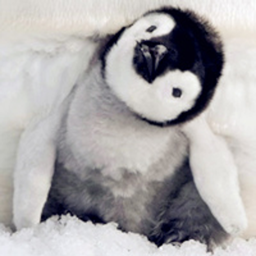

In [56]:
image

In [57]:
image = image.convert('RGB')
mask = np.asarray(mask)

lq, out_h, out_w = PIL2Tensor(image, upsacle=UPSCALE, min_size=MIN_SIZE)
lq = lq.unsqueeze(0).to(DEVICE)
reference = image.resize((out_w, out_h), Image.Resampling.BICUBIC)

mask = torch.from_numpy(np.array(mask, copy=True)).float()[None, None].to(DEVICE)
# restored = sample_latent(model, lq.unsqueeze(0).to(DEVICE), mask_tensor, prompt)

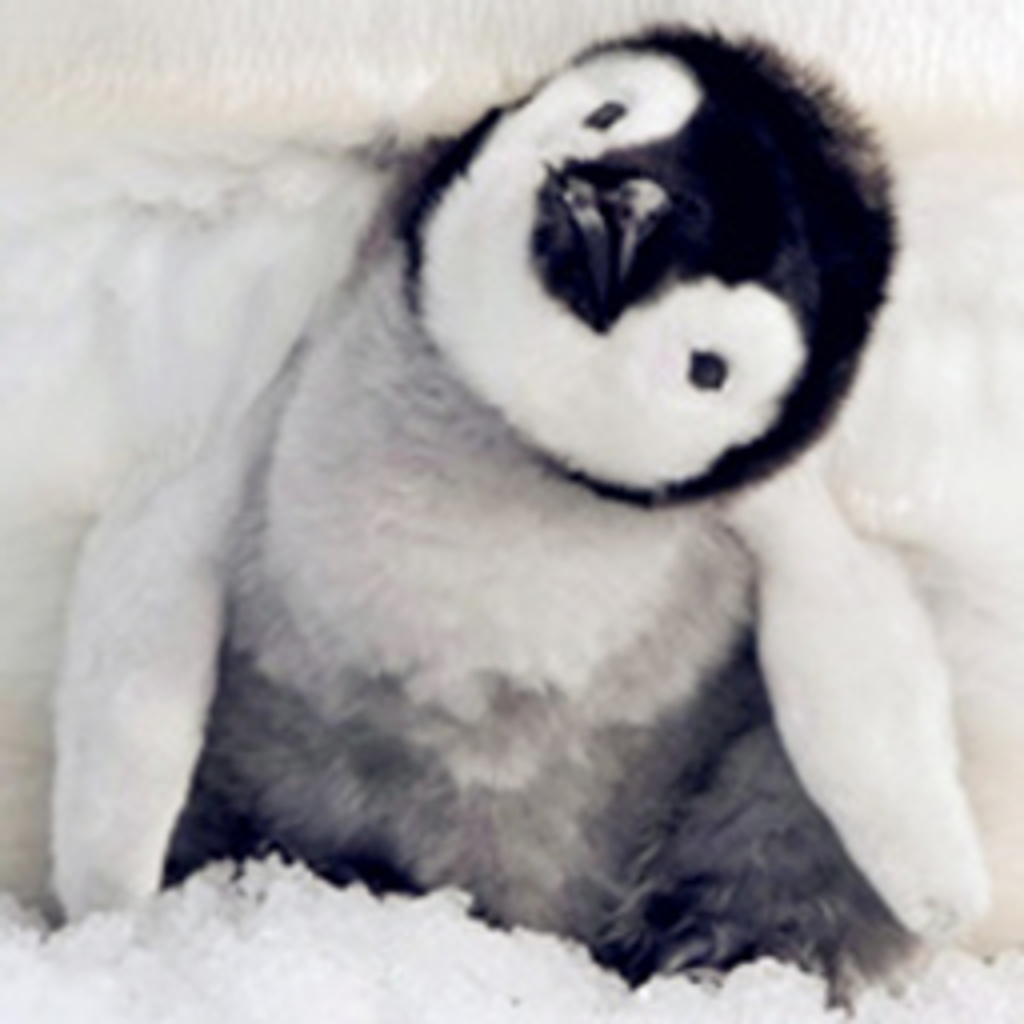

In [58]:
reference

In [59]:
mask.shape

torch.Size([1, 1, 256, 256])

In [60]:
z_control = model.encode_first_stage_with_denoise(lq, use_sample=False)
stage1 = model.decode_first_stage(z_control)
center = model.encode_first_stage(stage1)
z_ref = model.encode_first_stage(lq)

In [61]:
z_control.shape

torch.Size([1, 4, 128, 128])

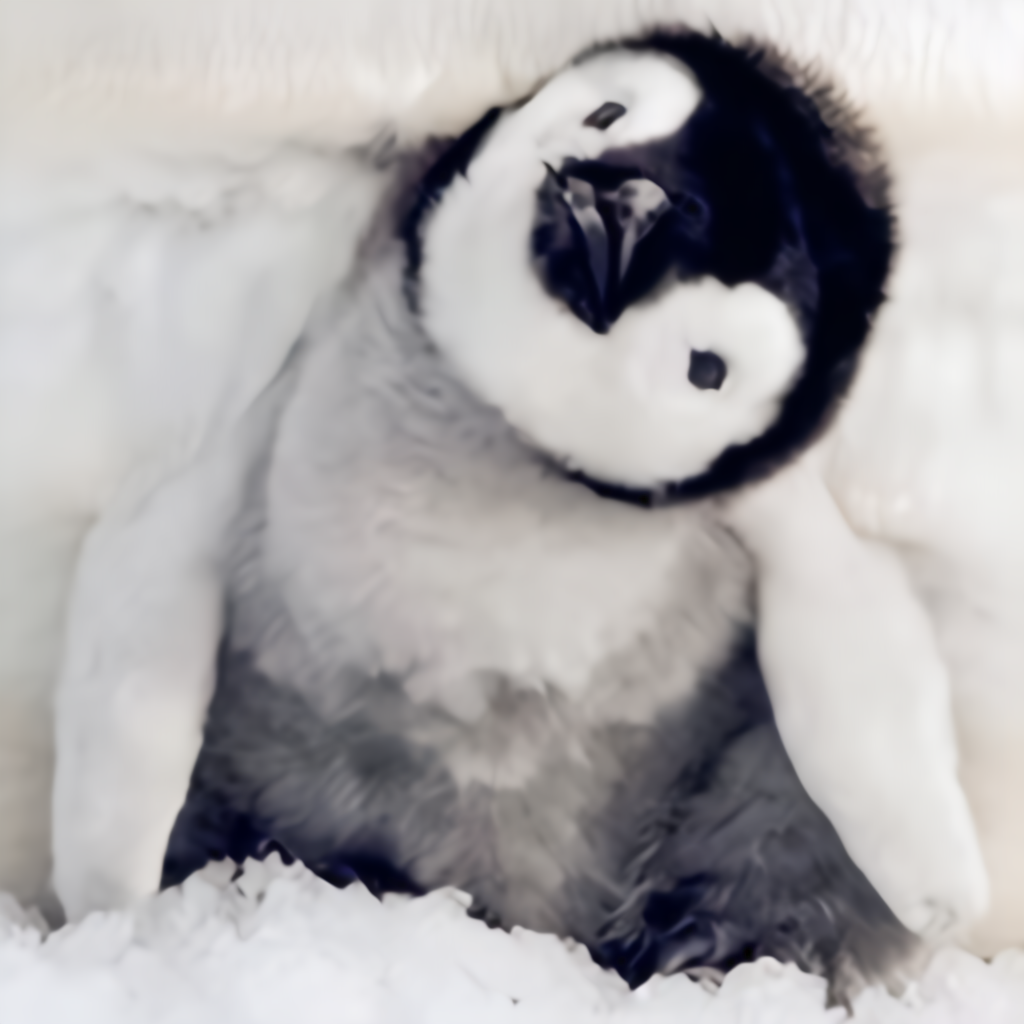

In [62]:
Tensor2PIL(stage1[0], 1024, 1024)

In [63]:
center.shape

torch.Size([1, 4, 128, 128])

In [64]:
mask_z = F.interpolate(mask.float(), size=z_control.shape[-2:], mode='area').to(z_control.dtype)
cond, uncond = model.prepare_condition(z_control.cpu(), [prompt], model.p_p, model.n_p, len(lq))
cond = {key: value.to(lq.device) for key, value in cond.items()}
uncond = {key: value.to(lq.device) for key, value in uncond.items()}

In [67]:
model.p_p

'Cinematic, High Contrast, highly detailed, taken using a Canon EOS R camera, hyper detailed photo - realistic maximum detail, 32k, Color Grading, ultra HD, extreme meticulous detailing, skin pore detailing, hyper sharpness, perfect without deformations.'

In [68]:
model.n_p

'painting, oil painting, illustration, drawing, art, sketch, oil painting, cartoon, CG Style, 3D render, unreal engine, blurring, dirty, messy, worst quality, low quality, frames, watermark, signature, jpeg artifacts, deformed, lowres, over-smooth'

# Sampling

In [83]:
@torch.inference_mode()
def sample_latent(model, lq, mask, prompt=''):
    seed_everything(SEED)
    z_control = model.encode_first_stage_with_denoise(lq, use_sample=False)
    stage1 = model.decode_first_stage(z_control)
    center = model.encode_first_stage(stage1)
    z_ref = model.encode_first_stage(lq)
    mask_z = F.interpolate(mask.float(), size=z_control.shape[-2:], mode='area').to(z_control.dtype)
    cond, uncond = model.prepare_condition(z_control.cpu(), [prompt], model.p_p, model.n_p, len(lq))
    cond = {key: value.to(lq.device) for key, value in cond.items()}
    uncond = {key: value.to(lq.device) for key, value in uncond.items()}

    sampler_params = model.sampler_config.params
    discretization = instantiate_from_config(sampler_params.discretization_config)
    guider_config = OmegaConf.create(OmegaConf.to_container(sampler_params.guider_config, resolve=True))
    guider_config.params.scale = CFG_SCALE_START
    guider_config.params.scale_min = CFG_SCALE
    guider = instantiate_from_config(guider_config)
    sigmas = discretization(STEPS, device=lq.device)

    x = torch.randn_like(z_control) * torch.sqrt(1 + sigmas[0] ** 2)
    sigma_max = 14.6146
    for step in range(len(sigmas) - 1):
        sigma = sigmas[step].expand(len(x))
        next_sigma = sigmas[step + 1].expand(len(x))
        gamma = min(S_CHURN / (len(sigmas) - 1), 2 ** 0.5 - 1)
        sigma_hat = sigma * (1 + gamma)
        if gamma > 0:
            x = x + torch.randn_like(x) * S_NOISE * (sigma_hat**2 - sigma**2).sqrt()[:, None, None, None]

        raw_uc = model.denoiser(model.model, x, sigma_hat, uncond, CONTROL_SCALE)
        raw_c = model.denoiser(model.model, x, sigma_hat, cond, CONTROL_SCALE)
        prediction = guider.dyn_thresh(
            raw_uc, raw_c, guider.scale_schedule(sigma_hat)
        )
        del raw_uc, raw_c
        
        if RESTORATION_SCALE > 0 and next_sigma[0] > 0.05:
            weight = (sigma / sigma_max) ** RESTORATION_SCALE
            prediction = prediction - (prediction - center) * weight[:, None, None, None]

        # prediction = mask_z * prediction + (1 - mask_z) * z_ref
        # Первую половину шагов SUPIR восстанавливает весь кадр.
        num_steps = len(sigmas) - 1
        warmup_steps = num_steps // 2
        strength = max(0.0, (step + 1 - warmup_steps) / (num_steps - warmup_steps))
        ref_weight = strength * (1 - mask_z)
        prediction = (1 - ref_weight) * prediction + ref_weight * z_ref
        
        derivative = (x - prediction) / sigma_hat[:, None, None, None]
        x = x + (next_sigma - sigma_hat)[:, None, None, None] * derivative

    restored = model.decode_first_stage(x)
    return wavelet_reconstruction(restored, stage1)


@torch.inference_mode()
def restore_image(model, image, mask, prompt=''):
    image = image.convert('RGB')
    mask = np.asarray(mask)
    if mask.shape != (image.height, image.width):
        raise ValueError('Маска должна иметь форму (H, W) входного LQ')
    values = set(np.unique(mask).tolist())
    if not values <= {0, 1}:
        raise ValueError('Маска должна быть бинарным массивом из 0 и 1')

    lq, out_h, out_w = PIL2Tensor(image, upsacle=UPSCALE, min_size=MIN_SIZE)
    reference = image.resize((out_w, out_h), Image.Resampling.BICUBIC)
    if values == {0}:
        return reference
    mask_tensor = torch.from_numpy(np.array(mask, copy=True)).float()[None, None].to(DEVICE)
    restored = sample_latent(model, lq.unsqueeze(0).to(DEVICE), mask_tensor, prompt)
    supir = Tensor2PIL(restored[0], out_h, out_w)
    output_mask = Image.fromarray((mask * 255).astype(np.uint8)).resize(
        reference.size, Image.Resampling.NEAREST)
    return Image.composite(supir, reference, output_mask)


In [80]:
@torch.inference_mode()
def sample_latent(model, lq, mask, prompt=''):
    seed_everything(SEED)
    z_control = model.encode_first_stage_with_denoise(lq, use_sample=False)
    stage1 = model.decode_first_stage(z_control)
    center = model.encode_first_stage(stage1)
    z_ref = model.encode_first_stage(lq)
    mask_z = F.interpolate(mask.float(), size=z_control.shape[-2:], mode='area').to(z_control.dtype)
    cond, uncond = model.prepare_condition(z_control.cpu(), [prompt], model.p_p, model.n_p, len(lq))
    cond = {key: value.to(lq.device) for key, value in cond.items()}
    uncond = {key: value.to(lq.device) for key, value in uncond.items()}

    sampler_params = model.sampler_config.params
    discretization = instantiate_from_config(sampler_params.discretization_config)
    guider_config = OmegaConf.create(OmegaConf.to_container(sampler_params.guider_config, resolve=True))
    guider_config.params.scale = CFG_SCALE_START
    guider_config.params.scale_min = CFG_SCALE
    guider = instantiate_from_config(guider_config)
    sigmas = discretization(STEPS, device=lq.device)

    x = torch.randn_like(z_control) * torch.sqrt(1 + sigmas[0] ** 2)
    sigma_max = 14.6146
    ref_rng = torch.Generator(device=z_ref.device).manual_seed(SEED + 1)
    ref_noise = torch.randn(
        z_ref.shape,
        device=z_ref.device,
        dtype=z_ref.dtype,
        generator=ref_rng,
    )
    num_steps = len(sigmas) - 1
    warmup_steps = num_steps // 2
    for step in range(len(sigmas) - 1):
        sigma = sigmas[step].expand(len(x))
        next_sigma = sigmas[step + 1].expand(len(x))
        gamma = min(S_CHURN / (len(sigmas) - 1), 2 ** 0.5 - 1)
        sigma_hat = sigma * (1 + gamma)
        if gamma > 0:
            x = x + torch.randn_like(x) * S_NOISE * (sigma_hat**2 - sigma**2).sqrt()[:, None, None, None]

        sigma_hat_view = sigma_hat[:, None, None, None]
        
        progress = max(0.0, (step + 1 - warmup_steps) / (num_steps - warmup_steps))
        if progress > 0:
            noisy_ref = z_ref + sigma_hat_view * ref_noise
            weight = 0.25 * progress * (1 - mask_z)
            x = x + weight * (noisy_ref - x)
        
        raw_uc = model.denoiser(model.model, x, sigma_hat, uncond, CONTROL_SCALE)
        raw_c = model.denoiser(model.model, x, sigma_hat, cond, CONTROL_SCALE)
        prediction = guider.dyn_thresh(
            raw_uc, raw_c, guider.scale_schedule(sigma_hat)
        )
        del raw_uc, raw_c
        
        if RESTORATION_SCALE > 0 and next_sigma[0] > 0.05:
            weight = (sigma / sigma_max) ** RESTORATION_SCALE
            prediction = prediction - (prediction - center) * weight[:, None, None, None]
        
        derivative = (x - prediction) / sigma_hat_view
        x = x + (next_sigma - sigma_hat)[:, None, None, None] * derivative

    restored = model.decode_first_stage(x)
    return wavelet_reconstruction(restored, stage1)


## Одно изображение

Поместите LQ-файл в `examples/input.png`. Выберите `MASK_KIND` из `zero`, `one`, `mixed`; результат сохранится в `results/`.


[rank: 0] Seed set to 1234


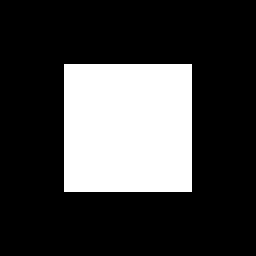

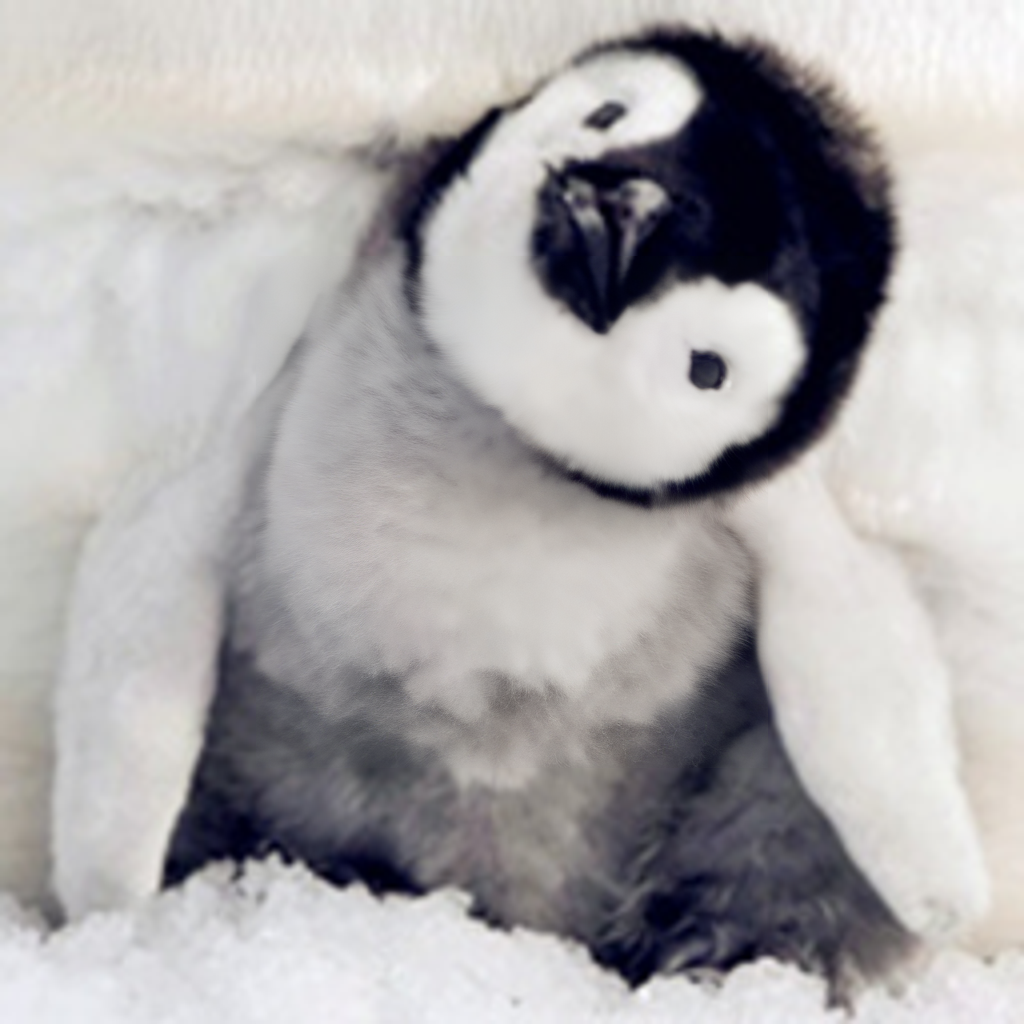

In [81]:
MASK_KIND = 'mixed'
image = Image.open(INPUT_IMAGE).convert('RGB').resize((256, 256))
mask = make_masks(image)[MASK_KIND]
result = restore_image(model, image, mask, PROMPT)
output_path = ROOT / f'results/{INPUT_IMAGE.stem}_{MASK_KIND}.png'
output_path.parent.mkdir(parents=True, exist_ok=True)
result.save(output_path)
display(Image.fromarray(mask * 255), result)


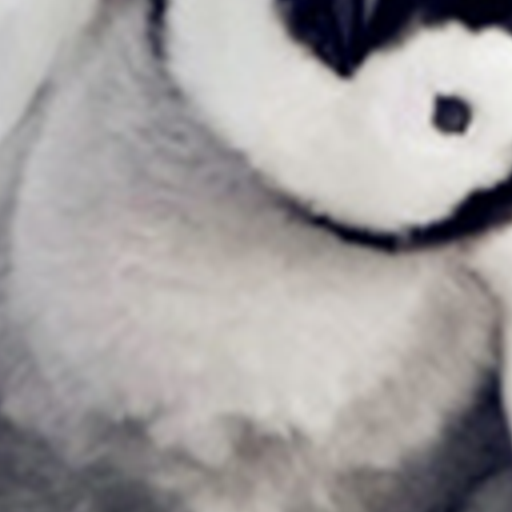

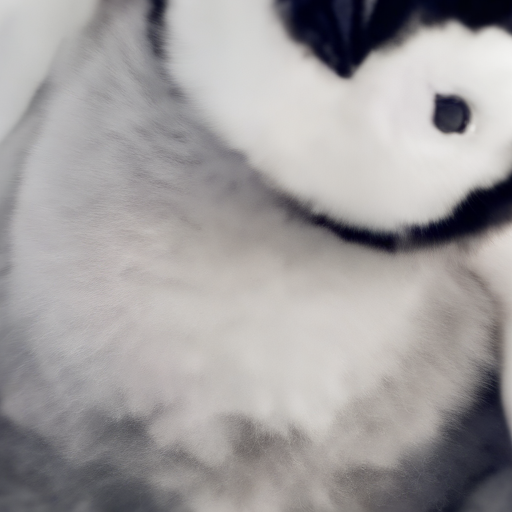

In [82]:
baseline = image.resize(result.size, Image.Resampling.BICUBIC)
mask_out = Image.fromarray(mask * 255).resize(
    result.size, Image.Resampling.NEAREST
)
box = mask_out.getbbox()
display(baseline.crop(box), result.crop(box))

[rank: 0] Seed set to 1234


маска внутри семплирования


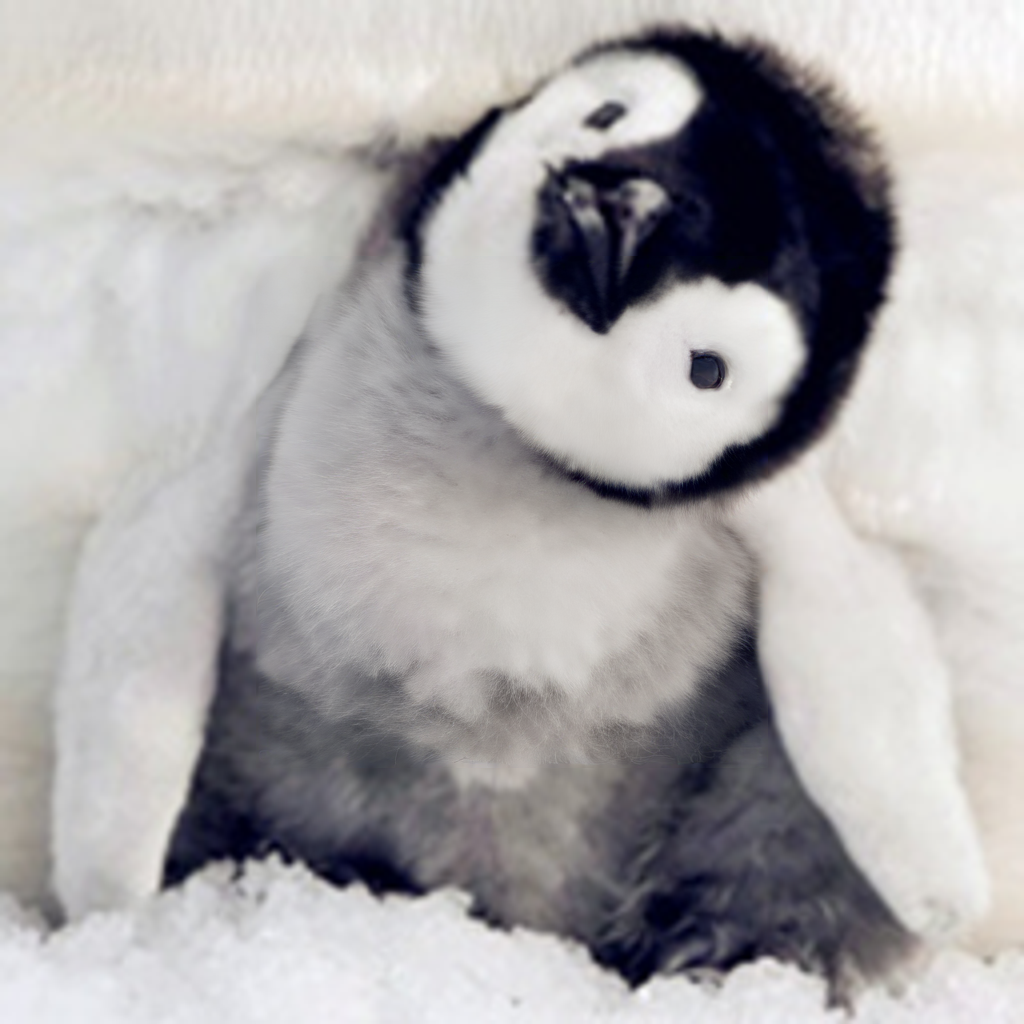

обычный SUPIR с маской после генерации


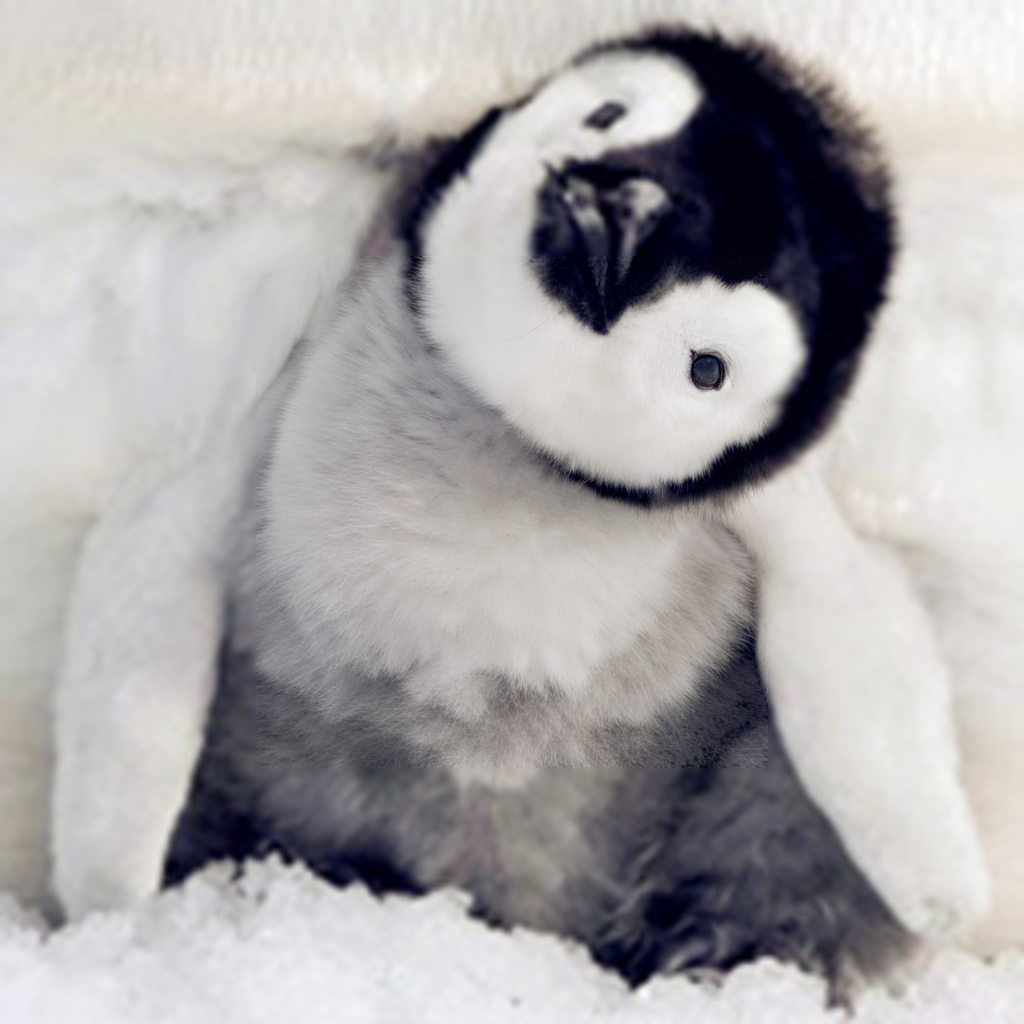

In [76]:
masked_sampling = result

full_supir = restore_image(model, image, np.ones_like(mask), PROMPT)
bicubic = image.resize(full_supir.size, Image.Resampling.BICUBIC)

output_mask = Image.fromarray(mask.astype(np.uint8) * 255).resize(
    full_supir.size, Image.Resampling.NEAREST
)
post_mask = Image.composite(full_supir, bicubic, output_mask)

comparison_path = output_path.with_name(f"{INPUT_IMAGE.stem}_post_mask.png")
post_mask.save(comparison_path)

left, top, right, bottom = output_mask.getbbox()
pad = 24
crop_box = (
    max(0, left - pad),
    max(0, top - pad),
    min(full_supir.width, right + pad),
    min(full_supir.height, bottom + pad),
)

print("маска внутри семплирования")
display(masked_sampling)

print("обычный SUPIR с маской после генерации")
display(post_mask)

inside = np.asarray(output_mask) > 0
a = np.asarray(masked_sampling, dtype=np.float32)
b = np.asarray(post_mask, dtype=np.float32)
diff = np.abs(a - b)

## Эксперимент: три маски х две деградации

In [ ]:
def make_lq(hr, degradation):
    small = (hr.width // UPSCALE, hr.height // UPSCALE)

    if degradation == "bicubic":
        return hr.resize(small, Image.Resampling.BICUBIC)

    if degradation == "blur_jpeg":
        blurred = hr.filter(ImageFilter.GaussianBlur(1.4))
        lq = blurred.resize(small, Image.Resampling.BICUBIC)

        with BytesIO() as stream:
            lq.save(stream, format="JPEG", quality=45)
            stream.seek(0)
            with Image.open(stream) as compressed:
                return compressed.convert("RGB")

    raise ValueError(f"Неизвестная деградация: {degradation}")

In [90]:
paths = sorted(
    p for p in GT_DIR.iterdir()
    if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
)
if len(paths) < MAX_IMAGES:
    raise ValueError(f"Нужно минимум {MAX_IMAGES} HR-изображения в {GT_DIR}")

experiment_dir = ROOT / "results/lab3"
experiment_dir.mkdir(parents=True, exist_ok=True)

cases = []
for path in paths[:MAX_IMAGES]:
    with Image.open(path) as source:
        hr = source.convert("RGB")

    if min(hr.size) < MIN_SIZE:
        raise ValueError(f"HR-изображение слишком маленькое: {path}")

    width = hr.width - hr.width % UPSCALE
    height = hr.height - hr.height % UPSCALE
    hr = hr.crop((0, 0, width, height))

    for degradation in ("bicubic", "blur_jpeg"):
        name = f"{path.stem}_{degradation}"
        lq = make_lq(hr, degradation)
        baseline = lq.resize(hr.size, Image.Resampling.BICUBIC)
        masks = make_masks(lq)
        mixed_mask = masks["mixed"]

        mixed = restore_image(model, lq, mixed_mask, PROMPT)
        full_supir = restore_image(model, lq, masks["one"], PROMPT)

        mask_hr = Image.fromarray(mixed_mask * 255).resize(
            hr.size, Image.Resampling.NEAREST
        )
        post_mask = Image.composite(full_supir, baseline, mask_hr)

        hr.save(experiment_dir / f"{name}_gt.png")
        lq.save(experiment_dir / f"{name}_lq.png")
        baseline.save(experiment_dir / f"{name}_bicubic.png")

        for variant, output, mask in (
            ("zero", baseline, masks["zero"]),
            ("mixed", mixed, mixed_mask),
            ("post_mask", post_mask, mixed_mask),
        ):
            output.save(experiment_dir / f"{name}_{variant}.png")
            Image.fromarray(mask * 255).save(
                experiment_dir / f"{name}_{variant}_mask.png"
            )
            cases.append((name, variant))

print(f"Сохранено {len(cases)} результатов в {experiment_dir}")

[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234
[rank: 0] Seed set to 1234


Сохранено 18 результатов в /nfs/home/vmironov/SUPIR-Inpainting/results/lab3


## Метрики

PSNR и LPIPS сравнивают результат с HR; CLIP-IQA оценивает изображение без эталона. Для смешанной маски метрики считаются по всему кадру; дополнительно сохраняется максимальная разность вне маски относительно bicubic (должна быть 0). LPIPS и CLIP-IQA работают на CPU, чтобы не занимать память SUPIR на GPU. Первая инициализация метрик может загрузить дополнительные веса.


In [91]:
import csv
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity
from torchmetrics.multimodal.clip_iqa import CLIPImageQualityAssessment

lpips_metric = LearnedPerceptualImagePatchSimilarity(net_type='alex', normalize=True).eval()
clip_iqa_metric = CLIPImageQualityAssessment().eval()

def tensor01(image):
    array = np.asarray(image.convert('RGB'), dtype=np.float32) / 255.0
    return torch.from_numpy(array.copy()).permute(2, 0, 1).unsqueeze(0)

rows = []
with torch.inference_mode():
    for name, mask_name in cases:
        gt = np.asarray(Image.open(experiment_dir / f'{name}_gt.png').convert('RGB'), dtype=np.float32)
        output = np.asarray(Image.open(experiment_dir / f'{name}_{mask_name}.png').convert('RGB'), dtype=np.float32)
        baseline = np.asarray(Image.open(experiment_dir / f'{name}_bicubic.png').convert('RGB'), dtype=np.float32)
        mask = np.asarray(Image.open(experiment_dir / f'{name}_{mask_name}_mask.png').resize(
            (gt.shape[1], gt.shape[0]), Image.Resampling.NEAREST))
        mse = np.mean((output - gt) ** 2)
        outside = np.abs(output - baseline)[mask == 0]
        lpips_metric.reset()
        clip_iqa_metric.reset()
        rows.append({
            'case': name, 'mask': mask_name,
            'psnr_db': float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse)),
            'lpips': float(lpips_metric(tensor01(Image.fromarray(output.astype(np.uint8))),
                                        tensor01(Image.fromarray(gt.astype(np.uint8)))).item()),
            'clip_iqa': float(clip_iqa_metric(tensor01(Image.fromarray(output.astype(np.uint8)))).item()),
            'max_diff_outside': float(outside.max()) if outside.size else None,
        })

metrics_path = experiment_dir / 'metrics.csv'
with metrics_path.open('w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
for row in rows:
    print(row)
print(metrics_path)

{'case': '01_bicubic', 'mask': 'zero', 'psnr_db': 18.115672896748617, 'lpips': 0.5381565093994141, 'clip_iqa': 0.7687914967536926, 'max_diff_outside': 0.0}
{'case': '01_bicubic', 'mask': 'mixed', 'psnr_db': 18.140656381584186, 'lpips': 0.4572845697402954, 'clip_iqa': 0.7610821723937988, 'max_diff_outside': 0.0}
{'case': '01_bicubic', 'mask': 'post_mask', 'psnr_db': 18.049327369311634, 'lpips': 0.4341079294681549, 'clip_iqa': 0.6669098138809204, 'max_diff_outside': 0.0}
{'case': '01_blur_jpeg', 'mask': 'zero', 'psnr_db': 17.462647488280048, 'lpips': 0.6787431240081787, 'clip_iqa': 0.7304933071136475, 'max_diff_outside': 0.0}
{'case': '01_blur_jpeg', 'mask': 'mixed', 'psnr_db': 17.396909141816874, 'lpips': 0.5756912231445312, 'clip_iqa': 0.6774817109107971, 'max_diff_outside': 0.0}
{'case': '01_blur_jpeg', 'mask': 'post_mask', 'psnr_db': 17.248562554396205, 'lpips': 0.5518450736999512, 'clip_iqa': 0.5864841938018799, 'max_diff_outside': 0.0}
{'case': '02_bicubic', 'mask': 'zero', 'psnr_d